# Credit risk data: exploration and preprocessing

**Goal.** In this notebook we prepare the *Give Me Some Credit* data for an Intelligent Decision Support System (IDSS). The IDSS will help a bank employee judge whether a customer should be given a loan, so we need data that is correct, complete and easy to explain.

**How we work.** We first look at the data, then fix what is wrong, and check every step straight after we take it. We never change or delete a value before we understand it. For every decision we explain why we take it, how we carry it out, and what the data looks like afterwards.

| Section | Step |
|---|---|
| 1 | Reading the data and declaring variables |
| 2 | Target population and working matrix |
| 3 | First descriptive analysis |
| 4 | Error detection and first data-quality report |
| 5 | Error correction |
| 6 | Train/test split |
| 7 | Missing data: diagnosis and imputation |
| 8 | Outliers |
| 9 | Derivation of new variables |
| 10 | Transformations |
| 11 | Feature selection and dimensionality reduction |
| 12 | Instance selection and class imbalance |
| 13 | Final descriptive analysis (data improvements) |
| 14 | Export and handover to the IDSS |

## 1. Reading the data and declaring variables

In [1]:
import pandas as pd

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.linear_model import BayesianRidge, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 40, "display.width", 160, "display.float_format", "{:,.3f}".format)

COLOR_NO_DEFAULT = "#2a78d6"
COLOR_DEFAULT = "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

In [3]:
credit = pd.read_csv("../data/GiveMeSomeCredit-training.csv")

In [4]:
credit.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

I see that MonthlyIncome anf NumberOfDependents contain plenty of missing data. I will now try to investigate why this is the case.

In [5]:
credit.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,"150,000.000","150,000.000","150,000.000","150,000.000","150,000.000","150,000.000","120,269.000","150,000.000","150,000.000","150,000.000","150,000.000","146,076.000"
mean,"75,000.500",0.067,6.048,52.295,0.421,353.005,"6,670.221",8.453,0.266,1.018,0.240,0.757
std,"43,301.415",0.250,249.755,14.772,4.193,"2,037.819","14,384.674",5.146,4.169,1.130,4.155,1.115
min,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,"37,500.750",0.000,0.030,41.000,0.000,0.175,"3,400.000",5.000,0.000,0.000,0.000,0.000
50%,"75,000.500",0.000,0.154,52.000,0.000,0.367,"5,400.000",8.000,0.000,1.000,0.000,0.000
75%,"112,500.250",0.000,0.559,63.000,0.000,0.868,"8,249.000",11.000,0.000,2.000,0.000,1.000
max,"150,000.000",1.000,"50,708.000",109.000,98.000,"329,664.000","3,008,750.000",58.000,98.000,54.000,98.000,20.000


In [6]:
print((credit["NumberOfDependents"]>10).sum())
print((credit["age"]<18).sum())

2
1


### Metadata

The file has no data dictionary, so we take the definitions from the original Kaggle competition, *Give Me Some Credit* (2011). We give every variable a short name so that tables and plots stay readable.

| Short name | Original name | Type | Meaning |
|---|---|---|---|
| `Default2y` | SeriousDlqin2yrs | Qualitative (binary, coded 0/1) | **Response:** 90+ days past due within 2 years |
| `RevUtil` | RevolvingUtilizationOfUnsecuredLines | Numerical (ratio) | Balance on credit cards and personal lines divided by credit limits |
| `Age` | age | Numerical (years) | Borrower age |
| `Late30_59` | NumberOfTime30-59DaysPastDueNotWorse | Numerical (count) | Times 30-59 days late, last 2 years |
| `Late60_89` | NumberOfTime60-89DaysPastDueNotWorse | Numerical (count) | Times 60-89 days late, last 2 years |
| `Late90` | NumberOfTimes90DaysLate | Numerical (count) | Times 90+ days late |
| `DebtRatioRaw` | DebtRatio | Numerical (ratio, *but see section 4.1*) | Monthly debt payments and living costs divided by monthly gross income |
| `MonthlyIncome` | MonthlyIncome | Numerical (currency) | Monthly gross income |
| `OpenLines` | NumberOfOpenCreditLinesAndLoans | Numerical (count) | Open loans and lines of credit |
| `RealEstateLines` | NumberRealEstateLoansOrLines | Numerical (count) | Mortgage and real-estate loans |
| `Dependents` | NumberOfDependents | Numerical (count) | Dependents, excluding the borrower |

`Unnamed: 0` is only a row number, so we drop it. Before that, we check that we read the whole file (150,000 rows and 12 columns), that the row number is unique, and that every feature is numeric.

In [7]:
RENAME = {
    "SeriousDlqin2yrs": "Default2y",
    "RevolvingUtilizationOfUnsecuredLines": "RevUtil",
    "age": "Age",
    "NumberOfTime30-59DaysPastDueNotWorse": "Late30_59",
    "DebtRatio": "DebtRatioRaw",
    "NumberOfOpenCreditLinesAndLoans": "OpenLines",
    "NumberOfTimes90DaysLate": "Late90",
    "NumberRealEstateLoansOrLines": "RealEstateLines",
    "NumberOfTime60-89DaysPastDueNotWorse": "Late60_89",
    "NumberOfDependents": "Dependents",
}
TARGET = "Default2y"
LATE_COLS = ["Late30_59", "Late60_89", "Late90"]

assert credit.shape == (150_000, 12), "the file was not read completely"
assert credit["Unnamed: 0"].is_unique, "row number is not an identifier"

raw = credit.drop(columns="Unnamed: 0").rename(columns=RENAME)
raw[TARGET] = raw[TARGET].astype("int8")

assert set(raw[TARGET].unique()) == {0, 1}
assert all(pd.api.types.is_numeric_dtype(t) for t in raw.dtypes)
print(raw.shape)
raw.head()

(150000, 11)


,Default2y,RevUtil,Age,Late30_59,DebtRatioRaw,MonthlyIncome,OpenLines,Late90,RealEstateLines,Late60_89,Dependents
0,1,0.766,45,2,0.803,"9,120.000",13,0,6,0,2.000
1,0,0.957,40,0,0.122,"2,600.000",4,0,0,0,1.000
2,0,0.658,38,1,0.085,"3,042.000",2,1,0,0,0.000
3,0,0.234,30,0,0.036,"3,300.000",5,0,0,0,0.000
4,0,0.907,49,1,0.025,"63,588.000",7,0,1,0,0.000


## 2. Target population and working matrix

Before we clean anything, we pin down who and what the data describes, because this limits every conclusion we draw later. We repeat these points in the final report.

**Which customers (rows).**
- The data is observational: 150,000 anonymised consumer borrowers, published in 2011. The currency is not stated; we assume dollars, since the competition comes from the US.
- Everyone in the file already received credit. Applicants the bank rejected are absent, so we never see how they would have behaved (*selection bias*, also called the reject-inference problem). As a result, the IDSS will be most reliable for applicants who look like past approved customers, and less reliable for applicants with little credit history or of a kind the bank used to reject.
- The data is neither German nor European, and we do not know when it was collected. Incomes and credit habits differ from those of a present-day European bank, so a real deployment would need recalibration on the bank's own data.
- We apply no inclusion filter and keep every borrower in the file.

**Which variables (columns).** We keep all 10 predictors and drop only the row number. Removing a variable later is cheap, while getting back one we dropped is not. We choose the final features in section 11, based on evidence.

**Sensitive variables.** `Age` is a sensitive attribute, and `Dependents` describes family situation. Credit scoring is a high-risk use under the EU AI Act, so we keep both for the analysis, mark them as sensitive, and measure in section 13 what leaving them out would cost. The file has no sex or nationality variable, so we cannot check fairness across those groups.

## 3. First descriptive analysis

We start with a plain summary of every variable, to see the scale of each one and to spot values that cannot be right.

In [8]:
default_rate = raw[TARGET].mean()
print(f"Default rate: {default_rate:.2%} ({raw[TARGET].sum():,} of {len(raw):,})")

summary = raw.drop(columns=TARGET).describe(percentiles=[.5, .99, .999]).T
summary["skew"] = raw.drop(columns=TARGET).skew()
summary["missing"] = raw.isna().sum()
summary[["count", "missing", "mean", "std", "min", "50%", "99%", "99.9%", "max", "skew"]]

Default rate: 6.68% (10,026 of 150,000)


,count,missing,mean,std,min,50%,99%,99.9%,max,skew
RevUtil,"150,000.000",0,6.048,249.755,0.000,0.154,1.093,"1,571.006","50,708.000",97.632
Age,"150,000.000",0,52.295,14.772,0.000,52.000,87.000,94.000,109.000,0.189
Late30_59,"150,000.000",0,0.421,4.193,0.000,0.000,4.000,98.000,98.000,22.597
DebtRatioRaw,"150,000.000",0,353.005,"2,037.819",0.000,0.367,"4,979.040","10,613.074","329,664.000",95.158
MonthlyIncome,"120,269.000",29731,"6,670.221","14,384.674",0.000,"5,400.000","25,000.000","78,395.748","3,008,750.000",114.040
OpenLines,"150,000.000",0,8.453,5.146,0.000,8.000,24.000,34.000,58.000,1.215
Late90,"150,000.000",0,0.266,4.169,0.000,0.000,3.000,98.000,98.000,23.087
RealEstateLines,"150,000.000",0,1.018,1.130,0.000,1.000,4.000,9.000,54.000,3.482
Late60_89,"150,000.000",0,0.240,4.155,0.000,0.000,2.000,98.000,98.000,23.332
Dependents,"146,076.000",3924,0.757,1.115,0.000,0.000,4.000,6.000,20.000,1.588


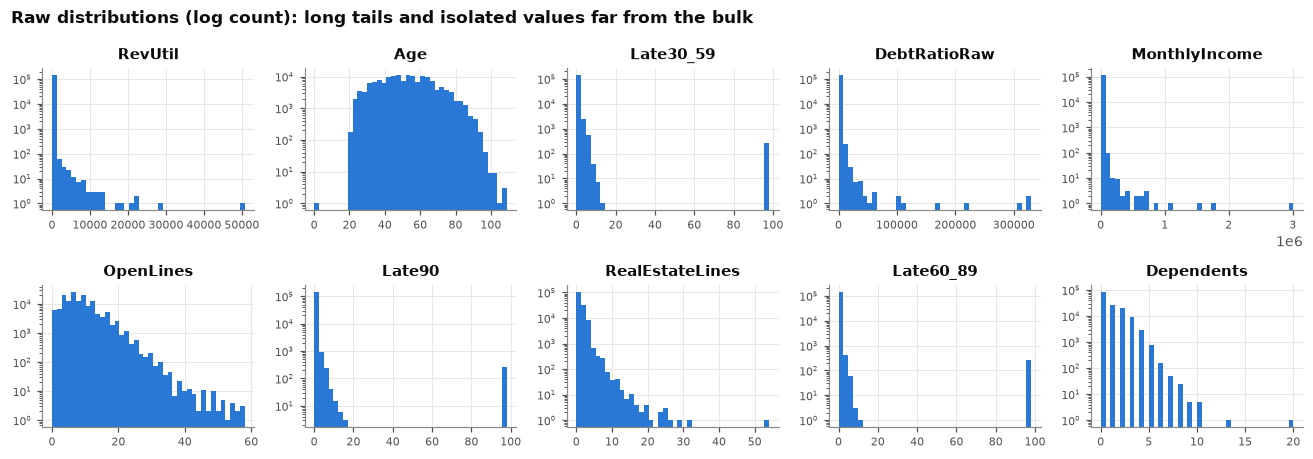

In [9]:
features = [c for c in raw.columns if c != TARGET]
fig, axes = plt.subplots(2, 5, figsize=(12, 4.2))
for ax, col in zip(axes.flat, features):
    ax.hist(raw[col].dropna(), bins=40, color=COLOR_NO_DEFAULT)
    ax.set_yscale("log")
    ax.set_title(col)
    ax.tick_params(labelsize=7)
fig.suptitle("Raw distributions (log count): long tails and isolated values far from the bulk",
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**What we see.**
- Only 6.7% of customers default (10,026 of 150,000), so the two classes are strongly unbalanced. We deal with this in section 12.
- Every numeric variable is skewed to the right: most customers have small values and a few have huge ones.
- Several maximums are impossible: a debt "ratio" of 329,664, a utilisation of 50,708, and 98 late payments in two years.

We investigate each of these in section 4 before changing anything.

## 4. Error detection and first data-quality report

In this section we only investigate. For each suspicious pattern we ask what could have caused it and what the customers involved look like, and only then decide what to do. We do not delete strange values on sight, because a value that looks wrong can turn out to be the most informative one in the file. We apply all the fixes together in section 5.

### 4.1 `DebtRatio` is not always a ratio

Customers with missing income have a median "ratio" of 1,159, which is impossible for a ratio. Our guess is that the file was built as `DebtRatio = MonthlyDebt / (MonthlyIncome + 1)`, with a missing income counted as 0. If that is true:
- when income is 0 or missing, the column holds the debt in dollars, so it is always a whole number;
- when income is 1, it holds whole or half numbers (the debt divided by 2);
- for everyone else, `DebtRatio * (income + 1)` gives a whole number of dollars.

We test all three below.

In [10]:
print(raw.groupby(raw["MonthlyIncome"].isna())["DebtRatioRaw"].median().rename("median DebtRatio by income missing"))


def is_whole(values, tol=1e-3):
    return (np.abs(values - values.round()) < tol).mean()


income_band = pd.Series(
    np.select(
        [raw["MonthlyIncome"].isna(), raw["MonthlyIncome"].eq(0), raw["MonthlyIncome"].eq(1)],
        ["missing", "income = 0", "income = 1"],
        "income > 1",
    ),
    index=raw.index,
)
recovered = raw["DebtRatioRaw"] * (raw["MonthlyIncome"].fillna(0) + 1)
pd.DataFrame({
    "rows": income_band.value_counts(),
    "DebtRatio is whole": raw["DebtRatioRaw"].groupby(income_band).apply(is_whole),
    "DebtRatio * income is whole": (raw["DebtRatioRaw"] * raw["MonthlyIncome"]).groupby(income_band).apply(is_whole),
    "DebtRatio * (income + 1) is whole": recovered.groupby(income_band).apply(is_whole),
})

MonthlyIncome
False       0.296
True    1,159.000
Name: median DebtRatio by income missing, dtype: float64


,rows,DebtRatio is whole,DebtRatio * income is whole,DebtRatio * (income + 1) is whole
income = 0,1634,1.000,1.000,1.000
income = 1,605,0.511,0.511,1.000
income > 1,118030,0.028,0.027,1.000
missing,29731,1.000,0.000,1.000


**What we found.** Our guess is right: multiplying by `income + 1` gives whole dollars in every group, while multiplying by `income` alone does not. In about 32,000 rows (a fifth of the file), the column called `DebtRatio` actually holds a monthly debt in dollars.

**Decision: we correct the column instead of treating these values as outliers.**
- *Why:* the debt values are valid, just stored in the wrong unit. If we treated them as outliers we would throw away good information, and customers with missing income would look as if they had enormous debt burdens.
- *How (section 5):* we recover the monthly debt exactly, as `MonthlyDebt = DebtRatio × (income + 1)`, and in section 9 we rebuild the true ratio from it.

### 4.2 Codes 96 and 98 in the lateness counts

Nobody can be late 98 times in two years, and the counts jump straight from at most 17 to 96. These look like codes for "unknown", but missing values can still carry information, so we look at who these customers are before choosing what to do.

In [11]:
coded = raw[LATE_COLS].isin([96, 98])
print("Largest real values:", {c: int(raw.loc[~coded[c], c].max()) for c in LATE_COLS})
print("Rows with a code in at least one column:", coded.any(axis=1).sum())
print("Rows with a code in all three columns:  ", coded.all(axis=1).sum())

pd.DataFrame({
    "coded rows": raw[coded.any(axis=1)].drop(columns=TARGET).median(),
    "other rows": raw[~coded.any(axis=1)].drop(columns=TARGET).median(),
}).T.assign(default_rate=[raw.loc[coded.any(axis=1), TARGET].mean(), raw.loc[~coded.any(axis=1), TARGET].mean()])

Largest real values: {'Late30_59': 13, 'Late60_89': 11, 'Late90': 17}
Rows with a code in at least one column: 269
Rows with a code in all three columns:   269


,RevUtil,Age,Late30_59,DebtRatioRaw,MonthlyIncome,OpenLines,Late90,RealEstateLines,Late60_89,Dependents,default_rate
coded rows,1.000,29.000,98.000,0.000,"2,168.500",0.000,98.000,0.000,98.000,0.000,0.546
other rows,0.153,52.000,0.000,0.367,"5,400.000",8.000,0.000,1.000,0.000,0.000,0.066


**What we found.** The codes always appear in all three lateness columns at once, together with no open credit lines and a utilisation of exactly 1. Above all, **55% of these 269 customers default**, about eight times the average.

**Decision: we turn the codes into missing values and add a flag, `LateCodeFlag`.**
- *Why:* 96 and 98 are not real counts, so we cannot leave them in, or a model would read them as "98 late payments". But we cannot delete these customers or set their counts to 0 either, because that would hide one of the strongest risk signals in the data.
- *How (section 5):* we set the three counts to missing (section 7 fills them with the median, 0) and give these customers `LateCodeFlag = 1`, so the risk signal survives in a clean form.

### 4.3 `RevUtil` above 1

Utilisation slightly above 1 is possible, since a customer can go over the limit. Values in the thousands are not. We look for the point where valid values end.

In [12]:
util_bands = pd.cut(raw["RevUtil"], [-.01, .5, 1, 2, 5, 10, 100, 1e6],
                    labels=["0-0.5", "0.5-1", "1-2", "2-5", "5-10", "10-100", ">100"])
table = raw.groupby(util_bands, observed=True).agg(rows=(TARGET, "size"), default_rate=(TARGET, "mean"))
table["share_whole_numbers"] = raw["RevUtil"].groupby(util_bands, observed=True).apply(lambda s: is_whole(s, 1e-6))
table

,rows,default_rate,share_whole_numbers
RevUtil,,,
0-0.5,108712,0.027,0.100
0.5-1,37967,0.153,0.271
1-2,2950,0.401,0.000
2-5,117,0.291,0.009
5-10,13,0.231,0.077
10-100,18,0.333,0.611
>100,223,0.049,0.996


**What we found.** Up to about 2, default risk rises with utilisation, as expected, and customers between 1 and 2 are real over-limit customers with a default rate of about 40%. Above 10 the values are almost all whole numbers, and above 100, where most of them sit, the default rate falls back to about average. This is the `DebtRatio` problem again: **dollar balances stored in a ratio column**.

**Decision: we set `RevUtil` above 10 to missing (241 rows).**
- *Why:* unlike the debt, we cannot convert these values back, because the file has no credit limit to divide by. A wrong value is worse than an unknown one, so we mark them as unknown. We keep the values from 2 to 10, because we cannot show that they are wrong.
- *How (section 5):* values above `UTIL_CEILING = 10` become missing, and section 7 fills them with the training median.

We also notice that 10,273 rows hold almost exactly 1 (0.9999999), a suspiciously precise value. Their default rate (18.7%) matches that of customers between 0.75 and 1 (17.9%), so the value behaves like a real utilisation. We keep it, and in section 9 we add a flag, `UtilAtOne`, so a model can use it.

### 4.4 `MonthlyIncome` of 0 or 1: hidden missing values?

A data entry system may store "unknown" as 0 or 1. If these were real incomes, these customers should look financially weak, so we compare them with their neighbours in income.

In [13]:
income_bands = pd.cut(raw["MonthlyIncome"], [-1, 0, 1, 100, 500, 1000, 2000, 5000, 10000, 1e8],
                      labels=["0", "1", "2-100", "101-500", "501-1k", "1k-2k", "2k-5k", "5k-10k", ">10k"])
by_income = (raw.assign(MonthlyDebt=recovered).groupby(income_bands, observed=True)
             .agg(rows=(TARGET, "size"), default_rate=(TARGET, "mean"),
                  median_age=("Age", "median"), median_monthly_debt=("MonthlyDebt", "median")))
missing_row = raw.assign(MonthlyDebt=recovered)[raw["MonthlyIncome"].isna()]
by_income.loc["missing"] = [len(missing_row), missing_row[TARGET].mean(),
                            missing_row["Age"].median(), missing_row["MonthlyDebt"].median()]
by_income

,rows,default_rate,median_age,median_monthly_debt
MonthlyIncome,,,,
0,1634,0.040,47.000,930.000
1,605,0.028,45.000,"1,200.000"
2-100,62,0.016,51.500,"1,070.500"
101-500,527,0.055,43.000,414.000
501-1k,1967,0.068,36.000,353.000
1k-2k,7208,0.106,47.000,520.000
2k-5k,43856,0.087,49.000,"1,070.000"
5k-10k,46091,0.060,51.000,"2,114.000"
>10k,18319,0.043,54.000,"3,369.000"


**What we found.** Incomes of 100 or less do not behave like low incomes. These customers carry about $1,000 of monthly debt, two to three times what the $101-500 band carries, and they default *less* than almost anyone else. They look much more like the customers with missing income than like low earners.

**Decision: we treat incomes of 100 or less as missing (2,301 rows).**
- *Why:* these numbers are most likely placeholders for "not declared". If we left them in, the model would learn that the poorest customers are the safest borrowers.
- *How (section 5):* incomes up to `INCOME_FLOOR = 100` become missing, and the customer gets `IncomeMissing = 1`, exactly like a blank income. We recover the debt (section 4.1) *before* this step, because the recovery needs the original income value.

### 4.5 Remaining checks

In [14]:
print("Age < 18:", raw.loc[raw["Age"] < 18, "Age"].to_dict())
print("Age > 100:", (raw["Age"] > 100).sum(), "rows, maximum", raw["Age"].max())
print("RealEstateLines > OpenLines:", (raw["RealEstateLines"] > raw["OpenLines"]).sum())
print("Dependents >= 10:", raw["Dependents"].value_counts().sort_index().loc[10:].to_dict())

dup_mask = raw.duplicated(keep=False)
dups = raw.assign(MonthlyDebt=recovered)[dup_mask]
print(f"\nExact duplicates: {raw.duplicated().sum()} surplus rows ({dup_mask.sum()} rows involved)")
print(f"  of the rows involved: {dups['MonthlyIncome'].isna().mean():.0%} have no income, "
      f"{dups['MonthlyDebt'].eq(0).mean():.0%} have zero debt")
print(f"  same predictors, different outcome: {raw.drop(columns=TARGET).duplicated().sum() - raw.duplicated().sum()} rows")

Age < 18: {65695: 0}
Age > 100: 13 rows, maximum 109
RealEstateLines > OpenLines: 0
Dependents >= 10: {10.0: 5, 13.0: 1, 20.0: 1}

Exact duplicates: 609 surplus rows (960 rows involved)
  of the rows involved: 85% have no income, 98% have zero debt
  same predictors, different outcome: 37 rows


- **`Age`:** one customer has age 0, while everyone else is 21 or older. This is a clear mistake, so we set it to missing and fill it with the median. Ages above 100 are rare but possible, so we keep them.
- **Credit lines:** consistent; nobody has more real-estate lines than open lines, so no action is needed.
- **Duplicates (609 rows): we keep them.** *Why:* they are not copied records. Each has its own ID, and they are almost empty profiles (no debt, no income, no history), so little apart from age and a few small counts can differ. Two different young customers can easily look identical. Deleting them would remove real customers with little credit history, a group the model already sees too little of.

### 4.6 First data-quality report

The table below collects every issue we found, how many customers it affects, and what we do about it.

In [15]:
quality = pd.DataFrame(
    [
        ("DebtRatio stores dollars, not a ratio", raw["MonthlyIncome"].isna() | raw["MonthlyIncome"].le(1),
         "Mistake (units)", "Correct: recover MonthlyDebt, rebuild ratio"),
        ("MonthlyIncome missing", raw["MonthlyIncome"].isna(), "Missing", "Impute (section 7), keep flag"),
        ("MonthlyIncome <= 100", raw["MonthlyIncome"].le(100), "Disguised missing", "Set missing, impute, keep flag"),
        ("Dependents missing", raw["Dependents"].isna(), "Missing", "Impute (section 7), keep flag"),
        ("Lateness codes 96/98", coded.any(axis=1), "Another population / missing code", "Set missing, impute, keep flag"),
        ("RevUtil > 10", raw["RevUtil"].gt(10), "Mistake (units), not correctable", "Set missing, impute"),
        ("Age = 0", raw["Age"].eq(0), "Mistake", "Set missing, impute"),
        ("Exact duplicates", raw.duplicated(), "Thin-file profiles", "Keep"),
    ],
    columns=["Issue", "mask", "Type", "Treatment"],
)
quality["Rows"] = quality["mask"].apply(lambda m: int(m.sum()))
quality["% of rows"] = quality["Rows"] / len(raw) * 100
quality["Default rate"] = quality["mask"].apply(lambda m: raw.loc[m, TARGET].mean())
quality.drop(columns="mask")[["Issue", "Rows", "% of rows", "Default rate", "Type", "Treatment"]]

,Issue,Rows,% of rows,Default rate,Type,Treatment
0,"DebtRatio stores dollars, not a ratio",31970,21.313,0.055,Mistake (units),"Correct: recover MonthlyDebt, rebuild ratio"
1,MonthlyIncome missing,29731,19.821,0.056,Missing,"Impute (section 7), keep flag"
2,MonthlyIncome <= 100,2301,1.534,0.037,Disguised missing,"Set missing, impute, keep flag"
3,Dependents missing,3924,2.616,0.046,Missing,"Impute (section 7), keep flag"
4,Lateness codes 96/98,269,0.179,0.546,Another population / missing code,"Set missing, impute, keep flag"
5,RevUtil > 10,241,0.161,0.071,"Mistake (units), not correctable","Set missing, impute"
6,Age = 0,1,0.001,0.000,Mistake,"Set missing, impute"
7,Exact duplicates,609,0.406,0.028,Thin-file profiles,Keep


## 5. Error correction

Here we apply the decisions from section 4, all in one function, `correct_errors`.

**How.** Every correction is a fixed rule (for example "an income of 100 or less means missing"), not a value learned from the data. This is why we can apply them before splitting the data into train and test, and why the IDSS can run exactly the same function on a new customer. We store the thresholds as constants (`INCOME_FLOOR`, `UTIL_CEILING`, `MIN_AGE`, `LATE_CODES`) so the IDSS can reuse them. The order matters: we recover the debt first, while the original income is still there. After the function, we check that every rule did what it should.

One caveat: we chose the thresholds after looking at the whole file, which includes the customers that later form the test set. They are a few coarse cut-offs that affect under 2% of rows, so we expect the effect on the final evaluation to be negligible.

In [16]:
INCOME_FLOOR = 100
UTIL_CEILING = 10
MIN_AGE = 18
LATE_CODES = [96, 98]


def correct_errors(df):
    """Rule-based corrections. Takes the raw schema and returns the cleaned schema."""
    out = df.copy()
    income = out["MonthlyIncome"]

    # Debt must be recovered first, while the original income is still available.
    out["MonthlyDebt"] = (out["DebtRatioRaw"] * (income.fillna(0) + 1)).round()
    out = out.drop(columns="DebtRatioRaw")

    is_code = out[LATE_COLS].isin(LATE_CODES)
    out["LateCodeFlag"] = is_code.any(axis=1).astype("int8")
    out["IncomeMissing"] = (income.isna() | income.le(INCOME_FLOOR)).astype("int8")
    out["DependentsMissing"] = out["Dependents"].isna().astype("int8")

    out[LATE_COLS] = out[LATE_COLS].mask(is_code)
    out["MonthlyIncome"] = income.where(income > INCOME_FLOOR)
    out["RevUtil"] = out["RevUtil"].where(out["RevUtil"] <= UTIL_CEILING)
    out["Age"] = out["Age"].where(out["Age"] >= MIN_AGE)
    return out


clean = correct_errors(raw)

assert len(clean) == len(raw)
assert clean["MonthlyDebt"].ge(0).all() and clean["MonthlyDebt"].notna().all()
assert clean[LATE_COLS].max().max() < 96
assert clean["MonthlyIncome"].min() > INCOME_FLOOR
assert clean["RevUtil"].max() <= UTIL_CEILING
assert clean["Age"].min() >= MIN_AGE
assert (clean["IncomeMissing"] == clean["MonthlyIncome"].isna()).all()
# The recovered debt must reproduce the original column.
check = clean["MonthlyDebt"] / (raw["MonthlyIncome"].fillna(0) + 1)
assert np.isclose(check, raw["DebtRatioRaw"], rtol=1e-3, atol=1e-3).mean() > 0.9999

print("All correction checks passed.")
clean[["RevUtil", "Age", "MonthlyIncome", "MonthlyDebt", "Late90", "Dependents"]].describe().T

All correction checks passed.


,count,mean,std,min,25%,50%,75%,max
RevUtil,"149,759.000",0.323,0.367,0.000,0.030,0.154,0.556,8.852
Age,"149,999.000",52.296,14.771,21.000,41.000,52.000,63.000,109.000
MonthlyIncome,"117,968.000","6,800.290","14,493.813",101.000,"3,500.000","5,483.000","8,333.000","3,008,750.000"
MonthlyDebt,"150,000.000","2,051.002","4,225.561",0.000,533.000,"1,551.000","2,804.000","478,486.000"
Late90,"149,731.000",0.090,0.486,0.000,0.000,0.000,0.000,17.000
Dependents,"146,076.000",0.757,1.115,0.000,0.000,0.000,1.000,20.000


**Result.** All checks pass and no customer is lost: we still have 150,000 rows. Instead of the broken ratio, the data now has `MonthlyDebt` in dollars (median $1,551), plus three flags (`LateCodeFlag`, `IncomeMissing`, `DependentsMissing`). The impossible values are gone: utilisation now tops out at 8.85, lateness counts at 17, and the youngest customer is 21. The number of missing cells goes *up*, from 33,655 to 37,005, on purpose: the wrong values are now marked as unknown, and section 7 fills them.

## 6. Train/test split

**Why now.** From here on we learn values from the data: medians, an imputation model, scaling parameters and feature rankings. If we learned them from all customers, information about the test customers would leak into the preparation, and the IDSS would look better on the test set than it really is.

**How.** We set 20% of customers aside as a test set, split so that both sets keep the same default rate (a stratified split). From now on we **fit everything on the training set only and apply it unchanged to the test set**, exactly as the IDSS will do with a new customer.

**Result.** 120,000 training and 30,000 test customers, both with a default rate of 6.68%.

In [17]:
train, test = train_test_split(clean, test_size=0.20, stratify=clean[TARGET], random_state=RANDOM_STATE)
print(f"train {train.shape}, default rate {train[TARGET].mean():.3%}")
print(f"test  {test.shape}, default rate {test[TARGET].mean():.3%}")

train (120000, 14), default rate 6.684%
test  (30000, 14), default rate 6.683%


## 7. Missing data

### 7.1 Diagnosis

Before we fill anything, we want to know *why* values are missing, because that decides whether filling them is safe. We count missing values per variable, per customer and per combination of variables (pattern), then run Little's MCAR test. The values we set to missing in section 5 appear here too. We study the patterns on the whole file, because nothing is learned from the data at this stage.

In [18]:
missing_by_var = pd.DataFrame({
    "missing": clean.isna().sum(),
    "%": clean.isna().mean() * 100,
}).query("missing > 0").sort_values("missing", ascending=False)
display(missing_by_var)

n_missing = clean.drop(columns=TARGET).isna().sum(axis=1)
display(pd.DataFrame({"individuals": n_missing.value_counts().sort_index(),
                      "default rate": clean[TARGET].groupby(n_missing).mean()})
        .rename_axis("missing values per individual"))

is_missing = clean.drop(columns=TARGET).isna()
patterns = is_missing.dot(is_missing.columns + " ").str.strip().replace("", "(complete)")
pd.DataFrame({"individuals": patterns.value_counts(),
              "default rate": clean[TARGET].groupby(patterns).mean()}).sort_values("individuals", ascending=False)

,missing,%
MonthlyIncome,32032,21.355
Dependents,3924,2.616
Late30_59,269,0.179
Late90,269,0.179
Late60_89,269,0.179
RevUtil,241,0.161
Age,1,0.001


,individuals,default rate
missing values per individual,,
0,117658,0.069
1,28122,0.055
2,3938,0.043
3,152,0.539
4,99,0.535
5,31,0.387


,individuals,default rate
(complete),117658,0.069
MonthlyIncome,27951,0.054
MonthlyIncome Dependents,3880,0.043
RevUtil,170,0.088
Late30_59 Late90 Late60_89,139,0.590
Late30_59 MonthlyIncome Late90 Late60_89,99,0.535
RevUtil MonthlyIncome,58,0.034
Late30_59 MonthlyIncome Late90 Late60_89 Dependents,31,0.387
RevUtil MonthlyIncome Dependents,13,0.000
Age,1,0.000


There are only ten patterns, and `Dependents` is missing **only** when income is missing too. This points to something systematic rather than chance, for example a whole section of the application form left blank. We check this formally with Little's test, whose null hypothesis is that values are missing completely at random (MCAR). We implement the test ourselves, using an EM algorithm to estimate the means and covariances despite the missing values. The test assumes roughly normal data, so we take the log of the skewed variables first.

In [19]:
def littles_mcar_test(frame, max_iter=200, tol=1e-5):
    """Little's MCAR test using EM estimates of the mean and covariance."""
    X = frame.to_numpy(dtype=float)
    n, p = X.shape
    observed = ~np.isnan(X)
    patterns_, group = np.unique(observed, axis=0, return_inverse=True)
    group = group.ravel()

    mu = np.nanmean(X, axis=0)
    sigma = np.diag(np.nanvar(X, axis=0))
    for _ in range(max_iter):
        sum_x, sum_xx = np.zeros(p), np.zeros((p, p))
        for k, obs in enumerate(patterns_):
            rows = X[group == k]
            mis = ~obs
            filled = rows.copy()
            extra = np.zeros((p, p))
            if mis.any():
                coef = sigma[np.ix_(mis, obs)] @ np.linalg.inv(sigma[np.ix_(obs, obs)])
                filled[:, mis] = mu[mis] + (rows[:, obs] - mu[obs]) @ coef.T
                extra[np.ix_(mis, mis)] = len(rows) * (sigma[np.ix_(mis, mis)] - coef @ sigma[np.ix_(obs, mis)])
            sum_x += filled.sum(axis=0)
            sum_xx += filled.T @ filled + extra
        new_mu = sum_x / n
        new_sigma = sum_xx / n - np.outer(new_mu, new_mu)
        converged = max(np.abs(new_mu - mu).max(), np.abs(new_sigma - sigma).max()) < tol
        mu, sigma = new_mu, new_sigma
        if converged:
            break

    d2, dof = 0.0, -p
    for k, obs in enumerate(patterns_):
        if not obs.any():
            continue
        rows = X[group == k][:, obs]
        diff = rows.mean(axis=0) - mu[obs]
        d2 += len(rows) * diff @ np.linalg.inv(sigma[np.ix_(obs, obs)]) @ diff
        dof += obs.sum()
    return d2, dof, stats.chi2.sf(d2, dof), len(patterns_)


little_frame = clean[["Age", "OpenLines", "RealEstateLines", "Dependents"]].copy()
for col in ["RevUtil", "MonthlyIncome", "MonthlyDebt", "Late30_59", "Late60_89", "Late90"]:
    little_frame[col] = np.log1p(clean[col])

d2, dof, p_value, n_patterns = littles_mcar_test(little_frame)
print(f"Little's test: d2 = {d2:,.0f}, df = {dof}, p = {p_value:.3g}, patterns = {n_patterns}")

Little's test: d2 = 16,131, df = 68, p = 0, patterns = 10


The test clearly rejects MCAR (p ≈ 0). With 150,000 rows, however, this test rejects even tiny departures, so we also look at how large the differences are. We split customers into "value missing" and "value observed" and compare the two groups variable by variable. We treat a standardised difference above about 0.2 as meaningful.

In [20]:
def compare_groups(frame, indicator, variables):
    rows = []
    miss = frame[indicator] == 1
    for col in variables:
        a, b = frame.loc[miss, col].dropna(), frame.loc[~miss, col].dropna()
        pooled = np.sqrt((a.var() + b.var()) / 2)
        rows.append({
            "variable": col,
            "median, missing": a.median(),
            "median, observed": b.median(),
            "std. mean difference": (a.mean() - b.mean()) / pooled,
            "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue,
        })
    return pd.DataFrame(rows).set_index("variable")


compare_vars = ["Age", "RevUtil", "MonthlyDebt", "OpenLines", "RealEstateLines", "Late30_59", "Late90"]
print("Income missing vs observed. Default rate:",
      clean.groupby("IncomeMissing")[TARGET].mean().round(4).to_dict())
display(compare_groups(clean, "IncomeMissing", compare_vars))

print("Dependents missing vs observed. Default rate:",
      clean.groupby("DependentsMissing")[TARGET].mean().round(4).to_dict())
display(compare_groups(clean, "DependentsMissing", compare_vars))

Income missing vs observed. Default rate: {0: 0.0701, 1: 0.0547}


,"median, missing","median, observed",std. mean difference,Mann-Whitney p
variable,,,,
Age,56.000,51.000,0.292,0.000
RevUtil,0.083,0.178,-0.146,0.000
MonthlyDebt,"1,144.000","1,658.000",-0.114,0.000
OpenLines,6.000,8.000,-0.315,0.000
RealEstateLines,1.000,1.000,-0.182,0.000
Late30_59,0.000,0.000,-0.125,0.000
Late90,0.000,0.000,-0.017,0.000


Dependents missing vs observed. Default rate: {0: 0.0674, 1: 0.0456}


,"median, missing","median, observed",std. mean difference,Mann-Whitney p
variable,,,,
Age,61.000,52.000,0.447,0.000
RevUtil,0.047,0.158,-0.236,0.000
MonthlyDebt,358.000,"1,578.000",-0.236,0.000
OpenLines,5.000,8.000,-0.629,0.000
RealEstateLines,0.000,1.000,-0.426,0.000
Late30_59,0.000,0.000,-0.187,0.000
Late90,0.000,0.000,-0.071,0.000


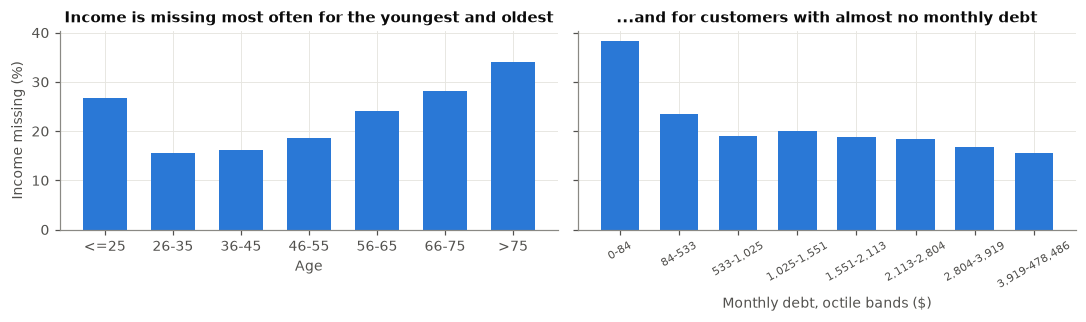

In [21]:
age_groups = pd.cut(clean["Age"], [17, 25, 35, 45, 55, 65, 75, 120],
                    labels=["<=25", "26-35", "36-45", "46-55", "56-65", "66-75", ">75"])
by_age = clean.groupby(age_groups, observed=True).agg(share=("IncomeMissing", "mean"))
by_debt = clean.groupby(pd.qcut(clean["MonthlyDebt"], 8, duplicates="drop"), observed=True).agg(
    share=("IncomeMissing", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
axes[0].bar(by_age.index.astype(str), by_age["share"] * 100, color=COLOR_NO_DEFAULT, width=0.65)
axes[0].set_title("Income is missing most often for the youngest and oldest")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income missing (%)")
labels = [f"{max(iv.left, 0):,.0f}-{iv.right:,.0f}" for iv in by_debt.index]
axes[1].bar(labels, by_debt["share"] * 100, color=COLOR_NO_DEFAULT, width=0.65)
axes[1].set_title("...and for customers with almost no monthly debt")
axes[1].set_xlabel("Monthly debt, octile bands ($)")
axes[1].tick_params(axis="x", labelsize=7, rotation=30)
fig.tight_layout()
plt.show()

**Diagnosis.** The values are not missing at random, so we cannot simply ignore the customers involved.

| Variable | Type | Evidence |
|---|---|---|
| `MonthlyIncome` | Not random | 21% missing, most often among the youngest and oldest customers and among those with almost no debt. These customers are older on average (median 56 vs 51), have fewer credit lines, and default less (5.5% vs 7.0%). Part of this is the hidden missing income from section 4.4 |
| `Dependents` | Not random | Missing only when income is missing too, in customers with little credit history (5 open lines vs 8, standardised difference -0.63, about $358 of debt vs $1,578). Default rate 4.6% |
| `Late*`, `RevUtil`, `Age` | Set to missing by us | Very few rows, with known causes (section 4) |

None of these values is "not applicable": everyone has an income and a number of dependents, so filling them in makes sense. The data shows that missingness depends on variables we can see, but it cannot rule out that it also depends on the hidden income itself, so we note this as a limitation. **Because the fact that a value is missing carries information, we keep a flag for every customer we fill in.**

### 7.2 Choosing an imputation method

**Why we do not drop incomplete customers.** That would remove a fifth of the customers, and section 7.1 shows that they differ from the rest, so the remaining data would no longer represent the bank's customers.

**How we choose.** We compare six methods, from simple to complex, and let the results decide. We take a sample of training customers whose income we know, hide some of their incomes, and measure how close each method gets to the true value. We hide incomes from the same kind of customers whose income is really missing (we estimate this from age, debt and credit profile), because hiding incomes at random would make the test easier than the real problem.

| Method | Idea |
|---|---|
| Global median | The same value for everyone (the median rather than the mean, since income is skewed) |
| Age-band median | The median of customers in the same age group |
| KNN | The average of the 10 most similar customers |
| MIMMI | Group customers into clusters (with k-means, since Ward does not scale to this size) and use each cluster's average |
| MICE, linear | Predict each incomplete variable from the others with linear regressions, in turns |
| MICE, boosted trees | The same, with a non-linear tree model |

Two rules hold for every method. We **never** use the target `Default2y` to fill a value, because we will not know it for a new applicant. And we impute income on a log scale, because it is so skewed. We run MICE once (single imputation) rather than creating several filled datasets, because the IDSS needs one fixed value per customer.

In [22]:
CORE_VARS = ["Age", "RevUtil_log", "MonthlyDebt_log", "OpenLines", "RealEstateLines", "LateAny"]
IMPUTE_INPUTS = CORE_VARS + ["Dependents"]


def imputation_frame(df):
    """Log-scale view used to model income. Never includes the response."""
    out = pd.DataFrame(index=df.index)
    out["Age"] = df["Age"]
    out["RevUtil_log"] = np.log1p(df["RevUtil"])
    out["MonthlyDebt_log"] = np.log1p(df["MonthlyDebt"])
    out["OpenLines"] = df["OpenLines"]
    out["RealEstateLines"] = df["RealEstateLines"]
    out["LateAny"] = df[LATE_COLS].sum(axis=1).gt(0).astype(float)
    out["Dependents"] = df["Dependents"]
    out["Income_log"] = np.log(df["MonthlyIncome"])
    return out


def median_imputer(frame):
    return frame["Income_log"].fillna(frame["Income_log"].median())


def age_band_imputer(frame):
    band = pd.cut(frame["Age"], [17, 25, 35, 45, 55, 65, 75, 120])
    return frame["Income_log"].fillna(frame.groupby(band, observed=True)["Income_log"].transform("median"))


def scaled(frame):
    return pd.DataFrame(StandardScaler().fit_transform(frame), index=frame.index, columns=frame.columns)


def knn_imputer(frame):
    columns = list(frame.columns)
    std = frame["Income_log"].std()
    mean = frame["Income_log"].mean()
    result = KNNImputer(n_neighbors=10).fit_transform(scaled(frame))
    return pd.Series(result[:, columns.index("Income_log")] * std + mean, index=frame.index)


def mimmi_imputer(frame, k=8):
    groups = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit_predict(scaled(frame[CORE_VARS]))
    return frame["Income_log"].fillna(frame.groupby(groups)["Income_log"].transform("mean"))


def mice_imputer(frame, estimator):
    columns = list(frame.columns)
    imputer = IterativeImputer(estimator=estimator, max_iter=10, tol=1e-3, random_state=RANDOM_STATE)
    return pd.Series(imputer.fit_transform(frame)[:, columns.index("Income_log")], index=frame.index)


def boosted_regressor():
    return HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=RANDOM_STATE)


METHODS = {
    "Global median": median_imputer,
    "Age-band median": age_band_imputer,
    "KNN (k=10)": knn_imputer,
    "MIMMI (k=8)": mimmi_imputer,
    "MICE, linear": lambda f: mice_imputer(f, BayesianRidge()),
    "MICE, boosted trees": lambda f: mice_imputer(f, boosted_regressor()),
}


# Rows are hidden in proportion to how likely real income is to be missing.
views = imputation_frame(train)
complete_rows = views.dropna().index
fill_for_propensity = views[CORE_VARS].fillna(views[CORE_VARS].median())
propensity = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
propensity.fit(fill_for_propensity, train["IncomeMissing"])
weights = propensity.predict_proba(fill_for_propensity.loc[complete_rows])[:, 1]
weights = weights / (1 - weights)

experiment = views.loc[rng.choice(complete_rows, size=25_000, replace=False)]
experiment_weights = pd.Series(weights, index=complete_rows).loc[experiment.index]
hidden = rng.choice(experiment.index, size=5_000, replace=False,
                    p=(experiment_weights / experiment_weights.sum()).to_numpy())
truth = experiment.loc[hidden, "Income_log"]
masked = experiment.copy()
masked.loc[hidden, "Income_log"] = np.nan

results = []
for name, method in METHODS.items():
    estimate = method(masked).loc[hidden]
    error = estimate - truth
    results.append({
        "method": name,
        "MAE (log income)": error.abs().mean(),
        "median abs. % error": (np.expm1(error.abs()).median()) * 100,
        "bias (log)": error.mean(),
        "imputed std / true std": estimate.std() / truth.std(),
    })
comparison = pd.DataFrame(results).set_index("method").sort_values("MAE (log income)")
comparison

,MAE (log income),median abs. % error,bias (log),imputed std / true std
method,,,,
"MICE, boosted trees",0.444,42.074,-0.012,0.554
KNN (k=10),0.473,45.723,-0.008,0.569
"MICE, linear",0.486,47.436,-0.024,0.533
MIMMI (k=8),0.511,50.911,0.012,0.358
Age-band median,0.516,51.209,0.086,0.316
Global median,0.547,54.908,0.104,0.000


**Results.** Boosted trees are the most accurate: a typical error of 42% against 55% for a global median, almost no bias, and the closest spread to real incomes.

**Decision: boosted trees for income, the median for everything else.**
- **Income.** *Why:* debt, age and credit profile tell us a lot about income, in a non-linear way, and the boosted model uses this best. *How:* we first fill the small gaps in the other variables with medians. Income is then the only incomplete variable, so the MICE loop reduces to a single regression: we train one boosted model on customers with a known income and use it to predict the rest. This model always gives the same answer for the same customer, stores no customer data (unlike KNN, which has to keep its neighbours), and is fast enough for a live form.
- **MIMMI** ranks low, but this is not a fair verdict on the method. Its step that uses expert knowledge needs a domain expert, which we did not have, so we only tested its clustering part.
- **`Dependents`.** *Why the median:* the median is 0, the value of 59% of customers, and only 2.6% of rows are affected. The flag `DependentsMissing` records which ones.
- **`Late*`, `RevUtil`, `Age`.** *Why the median:* at most 0.18% of rows are affected, so a simple choice is enough.

**Known limitation, important for the IDSS.** Even the best method is off by about 42% for a typical customer, and filled incomes have about half the spread of real ones. A filled income is a rough estimate, not a fact, so the IDSS should show it as an estimate and ask the employee for the real figure whenever possible.

### 7.3 Imputation

We fit the medians and the income model on the training set and apply them to both sets. Then we check that nothing is missing and that no observed value has changed.

In [23]:
SIMPLE_MEDIAN_COLS = ["Age", "RevUtil", "Dependents"] + LATE_COLS

# Fitted on train only.
medians = train[SIMPLE_MEDIAN_COLS].median()
fit_frame = train.copy()
fit_frame[SIMPLE_MEDIAN_COLS] = fit_frame[SIMPLE_MEDIAN_COLS].fillna(medians)
fit_frame = imputation_frame(fit_frame)
known_income = fit_frame["Income_log"].notna()
income_imputer = boosted_regressor().fit(fit_frame.loc[known_income, IMPUTE_INPUTS],
                                         fit_frame.loc[known_income, "Income_log"])


def impute(df, medians, income_imputer):
    """Fill missing values with statistics learned from the training data."""
    out = df.copy()
    out[SIMPLE_MEDIAN_COLS] = out[SIMPLE_MEDIAN_COLS].fillna(medians)
    inputs = imputation_frame(out)[IMPUTE_INPUTS]
    predicted = np.exp(income_imputer.predict(inputs))
    out["MonthlyIncome"] = out["MonthlyIncome"].fillna(pd.Series(predicted, index=out.index))
    return out


train_imp = impute(train, medians, income_imputer)
test_imp = impute(test, medians, income_imputer)

assert train_imp.isna().sum().sum() == 0 and test_imp.isna().sum().sum() == 0
assert (train_imp.loc[train["IncomeMissing"] == 0, "MonthlyIncome"]
        == train.loc[train["IncomeMissing"] == 0, "MonthlyIncome"]).all(), "observed values must not change"
print("No missing values left. Medians used:", medians.to_dict())
print(pd.DataFrame({
    "observed income": train["MonthlyIncome"].describe(percentiles=[.1, .5, .9]),
    "imputed income": train_imp.loc[train["IncomeMissing"] == 1, "MonthlyIncome"].describe(percentiles=[.1, .5, .9]),
}).round(0))

No missing values left. Medians used: {'Age': 52.0, 'RevUtil': 0.152409502, 'Dependents': 0.0, 'Late30_59': 0.0, 'Late60_89': 0.0, 'Late90': 0.0}
       observed income  imputed income
count       94,456.000      25,544.000
mean         6,783.000       5,125.000
std         14,654.000       2,113.000
min            101.000         920.000
10%          2,234.000       3,070.000
50%          5,454.000       4,632.000
90%         11,682.000       7,798.000
max      3,008,750.000      25,134.000


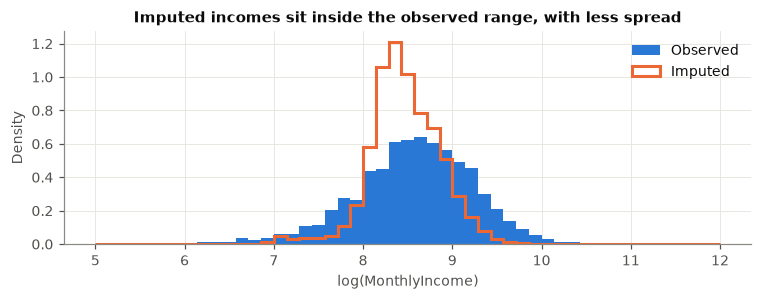

In [24]:
fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(5, 12, 50)
ax.hist(np.log(train["MonthlyIncome"].dropna()), bins=bins, density=True, color=COLOR_NO_DEFAULT, label="Observed")
ax.hist(np.log(train_imp.loc[train["IncomeMissing"] == 1, "MonthlyIncome"]), bins=bins, density=True,
        histtype="step", linewidth=2, color=COLOR_DEFAULT, label="Imputed")
ax.set_xlabel("log(MonthlyIncome)")
ax.set_ylabel("Density")
ax.set_title("Imputed incomes sit inside the observed range, with less spread")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Result.** No missing values remain in either set, and every observed income is unchanged. The 25,544 filled training incomes have a median of $4,632, against $5,454 for observed incomes, which fits the profile from section 7.1. All filled values lie between $920 and $25,134, so the model never invents extreme incomes; as the plot shows, they are more tightly grouped than real incomes.

## 8. Outliers

We look for outliers after correcting errors and filling missing values, because the multivariate check below needs complete data. Detection methods only point at candidates; for each one we decide what to do by looking at what the values mean.

### 8.1 Univariate: the boxplot rule on skewed data

The usual boxplot rule (Tukey's 1.5×IQR) assumes a roughly symmetric distribution. On skewed data like ours it flags many perfectly normal customers. To see how much of the flagging comes from skew alone, we apply the rule before and after a log transform.

,"flagged %, raw","flagged %, log","default rate, flagged raw"
MonthlyIncome,4.697,2.869,0.050
MonthlyDebt,3.426,9.779,0.116
RevUtil,0.362,0.109,0.424


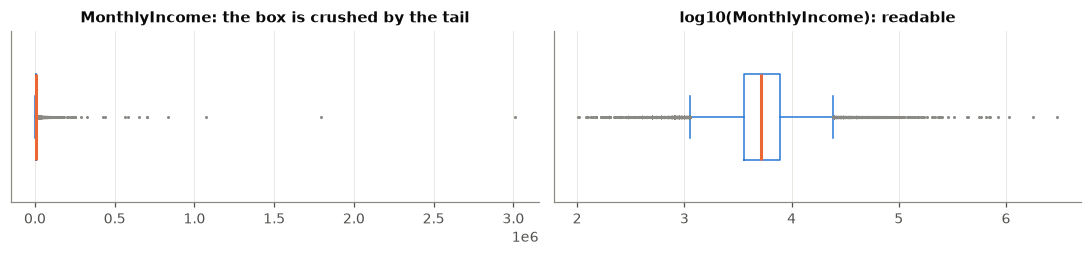

Highest incomes (for verification):


,Age,MonthlyIncome,MonthlyDebt,RevUtil,Default2y
73763,52.000,"3,008,750.000","4,423.000",0.007,0
137140,68.000,"1,794,060.000","4,980.000",0.000,0
50640,44.000,"1,072,500.000","4,866.000",0.469,0
122543,55.000,"835,040.000",123.000,0.042,0
93564,50.000,"702,500.000","5,808.000",0.072,0


Highest debts:


,Age,MonthlyIncome,MonthlyDebt,RevUtil,IncomeMissing,Default2y
55486,65.000,"7,223.000","474,705.000",0.229,0,0
139094,44.000,"12,487.000","357,560.000",0.514,0,0
60152,65.000,"14,450.732","329,664.000",0.000,1,0
36600,65.000,"7,276.050","326,442.000",0.002,1,0
127047,58.000,"22,094.464","307,001.000",0.034,1,0


In [25]:
def tukey_share(values):
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    return ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean() * 100


rows = {}
for col in ["MonthlyIncome", "MonthlyDebt", "RevUtil"]:
    values = train_imp[col].to_numpy(float)
    rows[col] = {"flagged %, raw": tukey_share(values), "flagged %, log": tukey_share(np.log1p(values)),
                 "default rate, flagged raw": None}
    q1, q3 = np.percentile(values, [25, 75])
    flagged = values > q3 + 1.5 * (q3 - q1)
    rows[col]["default rate, flagged raw"] = train_imp.loc[flagged, TARGET].mean()
display(pd.DataFrame(rows).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 2.4))
props = dict(flierprops=dict(marker=".", markersize=2, markeredgecolor="#8a8984"),
             medianprops=dict(color=COLOR_DEFAULT, linewidth=2),
             boxprops=dict(color=COLOR_NO_DEFAULT), whiskerprops=dict(color=COLOR_NO_DEFAULT),
             capprops=dict(color=COLOR_NO_DEFAULT))
axes[0].boxplot(train_imp["MonthlyIncome"], orientation="horizontal", widths=0.5, **props)
axes[0].set_title("MonthlyIncome: the box is crushed by the tail")
axes[0].set_yticks([])
axes[1].boxplot(np.log10(train_imp["MonthlyIncome"]), orientation="horizontal", widths=0.5, **props)
axes[1].set_title("log10(MonthlyIncome): readable")
axes[1].set_yticks([])
fig.tight_layout()
plt.show()

print("Highest incomes (for verification):")
display(train_imp.nlargest(5, "MonthlyIncome")[["Age", "MonthlyIncome", "MonthlyDebt", "RevUtil", TARGET]])
print("Highest debts:")
display(train_imp.nlargest(5, "MonthlyDebt")[["Age", "MonthlyIncome", "MonthlyDebt", "RevUtil", "IncomeMissing", TARGET]])

### 8.2 Bivariate

A combination of values can be rare even when each value on its own is ordinary. For a loan decision, the natural pair to check is debt against income.

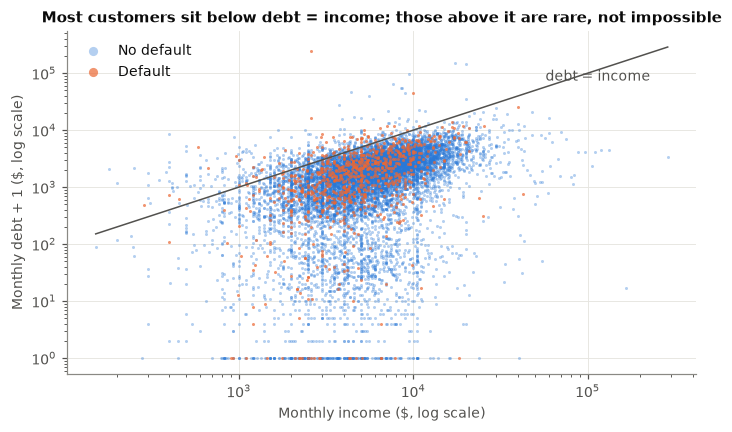

,rows,default_rate
<=0.3,48654,0.059
0.3-0.5,24941,0.064
0.5-1,16798,0.100
1-2,3144,0.137
2-5,701,0.094
>5,218,0.087


In [26]:
sample = train_imp[train_imp["IncomeMissing"] == 0].sample(12_000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6.5, 4))
for flag, color, label in [(0, COLOR_NO_DEFAULT, "No default"), (1, COLOR_DEFAULT, "Default")]:
    part = sample[sample[TARGET] == flag]
    ax.scatter(part["MonthlyIncome"], part["MonthlyDebt"] + 1, s=4, alpha=0.35 if flag == 0 else 0.7,
               color=color, label=label, linewidths=0)
limits = [sample["MonthlyIncome"].min(), sample["MonthlyIncome"].max()]
ax.plot(limits, limits, color="#52514e", linewidth=1)
ax.annotate("debt = income", (limits[1], limits[1]), xytext=(-80, -22), textcoords="offset points", color="#52514e")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Monthly income ($, log scale)")
ax.set_ylabel("Monthly debt + 1 ($, log scale)")
ax.set_title("Most customers sit below debt = income; those above it are rare, not impossible")
ax.legend(frameon=False, markerscale=3)
fig.tight_layout()
plt.show()

burden = train_imp["MonthlyDebt"] / train_imp["MonthlyIncome"]
known = train["IncomeMissing"] == 0
bands = pd.cut(burden[known], [-1, .3, .5, 1, 2, 5, 1e6], labels=["<=0.3", "0.3-0.5", "0.5-1", "1-2", "2-5", ">5"])
train_imp.loc[known].groupby(bands, observed=True).agg(rows=(TARGET, "size"), default_rate=(TARGET, "mean"))

**What we found.** Above a debt-to-income ratio of 1, customers owe more each month than they earn. This is unusual but real for people with savings or income the file does not show. Default risk is highest in the 1-2 band and then eases, so these customers carry information.

**Decision: we keep them.** The drop above 2 suggests that the very high ratios mix wealthy borrowers with doubtful figures. Instead of deleting them, we take the log in section 10, which limits their influence.

### 8.3 Multivariate: small clusters

A customer who is unusual on several variables at once ends up alone, or in a very small group, in a hierarchical clustering. Ward clustering does not scale to 120,000 rows, so we run it on a random sample of 4,000 customers. On a sample, this check can show what kinds of outliers exist, but not find all of them.

In [27]:
cluster_cols = ["Age", "OpenLines", "RealEstateLines", "Dependents"] + LATE_COLS
cluster_sample = train_imp.sample(4_000, random_state=RANDOM_STATE)
matrix = cluster_sample[cluster_cols].copy()
for col in ["RevUtil", "MonthlyIncome", "MonthlyDebt"]:
    matrix[col] = np.log1p(cluster_sample[col])

groups = pd.Series(fcluster(linkage(StandardScaler().fit_transform(matrix), "ward"), t=25, criterion="maxclust"),
                   index=cluster_sample.index)
sizes = groups.value_counts()
small = sizes[sizes <= 15].index
print("Cluster sizes:", sizes.sort_values().to_list())
profile = cluster_sample[cluster_cols + ["RevUtil", "MonthlyIncome", "MonthlyDebt"]].groupby(groups).median()
profile.insert(0, "rows", sizes)
profile.insert(1, "default_rate", cluster_sample.groupby(groups)[TARGET].mean())
print("Median profile of all customers vs the smallest clusters:")
display(pd.concat([cluster_sample[profile.columns[2:]].median().to_frame("everyone").T, profile.loc[small]])
        [list(profile.columns)])

Cluster sizes: [11, 15, 16, 25, 31, 40, 53, 54, 68, 77, 85, 112, 121, 129, 137, 159, 194, 233, 238, 302, 341, 347, 356, 360, 496]
Median profile of all customers vs the smallest clusters:


,rows,default_rate,Age,OpenLines,RealEstateLines,Dependents,Late30_59,Late60_89,Late90,RevUtil,MonthlyIncome,MonthlyDebt
everyone,NaN,NaN,52.000,8.000,1.000,0.000,0.000,0.000,0.000,0.147,"5,239.762","1,573.000"
23,15.000,0.133,55.000,22.000,8.000,0.000,0.000,0.000,0.000,0.092,"13,333.000","9,961.000"
21,11.000,0.000,60.000,40.000,2.000,0.000,0.000,0.000,0.000,0.281,"10,913.000","7,862.000"


**What we found.**
- *Clustering:* no customer ends up alone. The smallest clusters (11 and 15 customers) have very many credit lines (around 22-40) and high incomes and debts: unusual, but plausible.
- *Boxplot rule:* the log scale cuts the share of flagged incomes from 4.7% to 2.9%, as expected on skewed data. Debt goes the other way (3.4% to 9.8%), because on a log scale the customers with zero debt become the lower tail. Most importantly, the customers the rule flags on raw `RevUtil` default 42% of the time, six times the average. Deleting "outliers" by rule would have removed the riskiest customers in the data.

**Decision: we remove no customer.** Each kind of unusual value gets its own treatment instead:

| Kind | What we found | What we do |
|---|---|---|
| Mistake | `DebtRatio` in dollars; `RevUtil > 10`; `Age = 0` | Corrected or set to missing (section 5) |
| Code for "unknown" | 96/98 in the lateness counts; income up to 100 | Set to missing and filled, with a flag |
| A different group | The 269 customers with lateness codes, 55% default | Kept and marked by `LateCodeFlag` |
| Rare but informative | Over-limit customers (`RevUtil` 1-10) | Kept, with an `OverLimit` flag (section 9) |
| Extreme value | Income above $1M a month (3 training rows), monthly debt up to $474,705, ages above 100, 20 dependents | Kept. We cannot verify them and some may be mistakes (a debt of $474,705 against an income of $7,223 is doubtful), so the log transform in section 10 limits their weight instead |

## 9. Derivation of new variables

**Why.** A credit analyst does not reason with raw columns alone, but with questions like "how much of their income goes to debt?" or "how much is left at the end of the month?". We create these variables so that both the model and the employee can use them. We do it only now, after filling missing values, because a variable built from a missing value would be missing too.

**How.** One function, `derive`, applied in the same way to both sets:

| Variable | Definition | What it tells us |
|---|---|---|
| `DebtRatio` | `MonthlyDebt / MonthlyIncome` | The real ratio, now valid for every customer |
| `SavingCapacity` | `MonthlyIncome - MonthlyDebt` | Money left each month to repay a loan |
| `IncomePerPerson` | `MonthlyIncome / (Dependents + 1)` | Income adjusted to household size (sensitive, see section 2) |
| `LateTotal` | Sum of the three lateness counts | Overall payment history |
| `SeriousLate` | 1 if ever 60+ days late | Severe trouble in the past |
| `NonRealEstateLines` | `OpenLines - RealEstateLines` | Consumer credit, without mortgages |
| `OverLimit` | 1 if `RevUtil > 1` | Over the credit limit |
| `UtilAtOne` | 1 if `RevUtil` is about 1 | The 0.9999999 value from section 4.3 |

For customers with a filled income, `DebtRatio`, `SavingCapacity` and `IncomePerPerson` are estimates too. We keep `IncomeMissing` as a feature so that both the model and the employee can see this.

In [28]:
def derive(df):
    out = df.copy()
    out["DebtRatio"] = out["MonthlyDebt"] / out["MonthlyIncome"]
    out["SavingCapacity"] = out["MonthlyIncome"] - out["MonthlyDebt"]
    out["IncomePerPerson"] = out["MonthlyIncome"] / (out["Dependents"] + 1)
    out["LateTotal"] = out[LATE_COLS].sum(axis=1)
    out["SeriousLate"] = (out["Late60_89"] + out["Late90"]).gt(0).astype("int8")
    out["NonRealEstateLines"] = out["OpenLines"] - out["RealEstateLines"]
    out["OverLimit"] = out["RevUtil"].gt(1).astype("int8")
    out["UtilAtOne"] = (out["RevUtil"] - 1).abs().lt(1e-5).astype("int8")
    return out


train_ready = derive(train_imp)
test_ready = derive(test_imp)

assert np.isfinite(train_ready.drop(columns=TARGET).to_numpy(float)).all()
assert np.isfinite(test_ready.drop(columns=TARGET).to_numpy(float)).all()
assert train_ready["NonRealEstateLines"].ge(0).all()

BINARY = ["LateCodeFlag", "IncomeMissing", "DependentsMissing", "SeriousLate", "OverLimit", "UtilAtOne"]
NUMERIC = [c for c in train_ready.columns if c not in BINARY + [TARGET]]
print(len(NUMERIC), "numeric and", len(BINARY), "binary features")
train_ready[BINARY + [TARGET]].groupby(TARGET).mean().T.rename(columns={0: "share, no default", 1: "share, default"})

15 numeric and 6 binary features


Default2y,"share, no default","share, default"
LateCodeFlag,0.001,0.015
IncomeMissing,0.216,0.173
DependentsMissing,0.027,0.017
SeriousLate,0.060,0.458
OverLimit,0.013,0.121
UtilAtOne,0.060,0.192


**Result.** We now have 21 features, 15 numeric and 6 binary flags, with no missing or infinite values. The table shows that the new flags separate the classes well: 46% of defaulters have been 60+ days late before (`SeriousLate`), against 6% of non-defaulters, and 12% are over their limit (`OverLimit`), against 1.3%.

## 10. Transformations

We change the values only as much as the models need, and keep the original units available.

- **Units:** nothing left to do. Since section 5, money is in monthly dollars and ratios are true ratios.
- **Logarithm.** *Why:* income, debt and the ratios are very skewed (income has a skew of 136), so a few huge values dominate distances and linear models. *How:* we apply `log1p` (the log of 1 + x, which also works for zeros). It shrinks extreme values without removing or capping any customer. `SavingCapacity` can be negative, so it gets a signed log.
- **Standardisation.** *Why:* logistic regression and KNN are sensitive to the scale of each variable. *How:* we rescale every numeric feature to mean 0 and standard deviation 1, using the training means and standard deviations.
- **Discretisation: we do not use it.** Cutting a variable into bands throws information away, and none of our variables has natural groups that would justify it.

**We keep two versions of the data.** The **readable** version stays in original units: tree models work well on it, and the IDSS can explain a decision to the employee in dollars. The **model** version is logged and standardised, for scale-sensitive methods.

In [29]:
LOG_COLS = ["RevUtil", "MonthlyIncome", "MonthlyDebt", "DebtRatio", "IncomePerPerson",
            "LateTotal", "Dependents", "RealEstateLines"] + LATE_COLS
SIGNED_LOG_COLS = ["SavingCapacity"]


def log_transform(df):
    out = df.copy()
    out[LOG_COLS] = np.log1p(out[LOG_COLS])
    out[SIGNED_LOG_COLS] = np.sign(out[SIGNED_LOG_COLS]) * np.log1p(out[SIGNED_LOG_COLS].abs())
    return out


scaler = StandardScaler().fit(log_transform(train_ready)[NUMERIC])


def to_model_scale(df):
    out = log_transform(df)
    out[NUMERIC] = scaler.transform(out[NUMERIC])
    return out


train_model = to_model_scale(train_ready)
test_model = to_model_scale(test_ready)

skew = pd.DataFrame({"skew, readable": train_ready[NUMERIC].skew(), "skew, model": train_model[NUMERIC].skew()})
assert np.allclose(train_model[NUMERIC].mean(), 0, atol=1e-6) and np.allclose(train_model[NUMERIC].std(), 1, atol=1e-3)
skew

,"skew, readable","skew, model"
RevUtil,1.454,0.809
Age,0.187,0.187
Late30_59,4.282,2.524
MonthlyIncome,136.028,-0.257
OpenLines,1.229,1.229
Late90,9.357,5.071
RealEstateLines,3.753,0.238
Late60_89,7.604,4.971
Dependents,1.636,0.876
MonthlyDebt,48.944,-1.760


**Result.** The table compares the skew before and after. Income goes from 136 to -0.26 and the debt ratio from 84 to 2.9, so the extreme values no longer dominate. The lateness counts stay somewhat skewed (2.5 to 5) because most customers have never been late; this is real, so we leave it. All numeric model features now have mean 0 and standard deviation 1 on the training set.

## 11. Feature selection and dimensionality reduction

**Why.** 21 features are manageable for a model, but an employee needs a short list of variables that each say something different. We want to drop the features that repeat others or add nothing.

**How.** We rank the features on the training set with four kinds of criteria, so that no single method decides:
- **Statistical tests:** Kruskal-Wallis for numeric features (it does not need normal data) and chi-squared for the flags.
- **Information-based scores:** mutual information and Relief.
- **Inside a model:** L1 (LASSO) logistic regression, which sets the coefficients of useless features to exactly 0.
- **Search with a model:** recursive feature elimination (RFECV), which removes features one at a time and keeps the set with the best cross-validated AUC.

With 120,000 rows almost every p-value is close to 0, however weak the effect, so p-values alone cannot rank features. Next to them we report an effect size that works for numeric and binary features alike: the single-variable Gini coefficient, `|2 × AUC - 1|`, where 0 means no signal and 1 perfect separation.

For Relief we follow the original algorithm (Kira & Rendell, 1992): a feature gains weight when it differs between a customer and their nearest neighbour from the *other* class, and loses weight when it differs from their nearest neighbour of the *same* class.

In [30]:
ALL_FEATURES = NUMERIC + BINARY
X_train, y_train = train_model[ALL_FEATURES], train_model[TARGET]
n_train = len(X_train)


def statistical_tests(X, y):
    rows = {}
    for col in NUMERIC:
        h, p = stats.kruskal(X.loc[y == 0, col], X.loc[y == 1, col])
        rows[col] = {"test": "Kruskal-Wallis", "p": p, "gini": abs(2 * roc_auc_score(y, X[col]) - 1)}
    for col in BINARY:
        table = pd.crosstab(X[col], y)
        chi2, p, _, _ = stats.chi2_contingency(table)
        rows[col] = {"test": "chi2", "p": p, "gini": abs(2 * roc_auc_score(y, X[col]) - 1)}
    return pd.DataFrame(rows).T


def relief(X, y, n_samples=3_000):
    values = ((X - X.min()) / (X.max() - X.min())).to_numpy(float)
    labels = y.to_numpy()
    nn = {c: NearestNeighbors(n_neighbors=2).fit(values[labels == c]) for c in (0, 1)}
    pools = {c: values[labels == c] for c in (0, 1)}
    picks = rng.choice(len(values), n_samples, replace=False)
    weights = np.zeros(values.shape[1])
    for c in (0, 1):
        rows = values[picks[labels[picks] == c]]
        hit = pools[c][nn[c].kneighbors(rows, return_distance=False)[:, 1]]
        miss = pools[1 - c][nn[1 - c].kneighbors(rows, n_neighbors=1, return_distance=False)[:, 0]]
        weights += np.abs(rows - miss).sum(axis=0) - np.abs(rows - hit).sum(axis=0)
    return pd.Series(weights / n_samples, index=X.columns)


def balanced_sample(X, y, n_negative_per_positive=3):
    positives = y.index[y == 1]
    negatives = y[y == 0].sample(len(positives) * n_negative_per_positive, random_state=RANDOM_STATE).index
    keep = positives.union(negatives)
    return X.loc[keep], y.loc[keep]


ranking = statistical_tests(X_train, y_train)
ranking["mutual info"] = mutual_info_classif(X_train.sample(30_000, random_state=RANDOM_STATE),
                                             y_train.sample(30_000, random_state=RANDOM_STATE),
                                             discrete_features=[c in BINARY for c in ALL_FEATURES],
                                             random_state=RANDOM_STATE)
ranking["relief"] = relief(*balanced_sample(X_train, y_train))

lasso = LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.002, class_weight="balanced", max_iter=300)
lasso.fit(X_train, y_train)
ranking["L1 coef"] = pd.Series(lasso.coef_[0], index=ALL_FEATURES)

wrapper_X = X_train.sample(30_000, random_state=RANDOM_STATE)
wrapper = RFECV(LogisticRegression(max_iter=500, class_weight="balanced"), step=1, min_features_to_select=5,
                cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc")
wrapper.fit(wrapper_X, y_train.loc[wrapper_X.index])
ranking["RFE rank"] = pd.Series(wrapper.ranking_, index=ALL_FEATURES)

for col in ["gini", "mutual info", "relief"]:
    ranking[f"rank {col}"] = pd.to_numeric(ranking[col]).rank(ascending=False)
ranking["rank L1"] = ranking["L1 coef"].abs().rank(ascending=False)
ranking["mean rank"] = ranking[["rank gini", "rank mutual info", "rank relief", "rank L1"]].mean(axis=1)
ranking = ranking.sort_values("mean rank")
print(f"RFECV keeps {wrapper.n_features_} features; best CV AUC {wrapper.cv_results_['mean_test_score'].max():.4f}")
ranking[["test", "p", "gini", "mutual info", "relief", "L1 coef", "RFE rank", "mean rank"]]

RFECV keeps 16 features; best CV AUC 0.8610


,test,p,gini,mutual info,relief,L1 coef,RFE rank,mean rank
RevUtil,Kruskal-Wallis,0.000,0.556,0.040,0.006,0.693,1,2.750
Age,Kruskal-Wallis,0.000,0.263,0.008,0.012,-0.239,1,4.500
LateTotal,Kruskal-Wallis,0.000,0.534,0.049,0.002,0.574,1,4.500
Late90,Kruskal-Wallis,0.000,0.302,0.030,0.003,0.167,4,6.250
SavingCapacity,Kruskal-Wallis,0.000,0.247,0.007,0.003,-0.124,5,8.000
IncomePerPerson,Kruskal-Wallis,0.000,0.212,0.006,0.006,-0.041,1,8.500
Late60_89,Kruskal-Wallis,0.000,0.231,0.022,0.002,0.092,1,8.750
OpenLines,Kruskal-Wallis,0.000,0.095,0.005,0.008,0.140,1,9.500
Late30_59,Kruskal-Wallis,0.000,0.360,0.029,0.001,0.000,1,10.000
SeriousLate,chi2,0.000,0.398,0.035,0.000,0.000,1,10.125


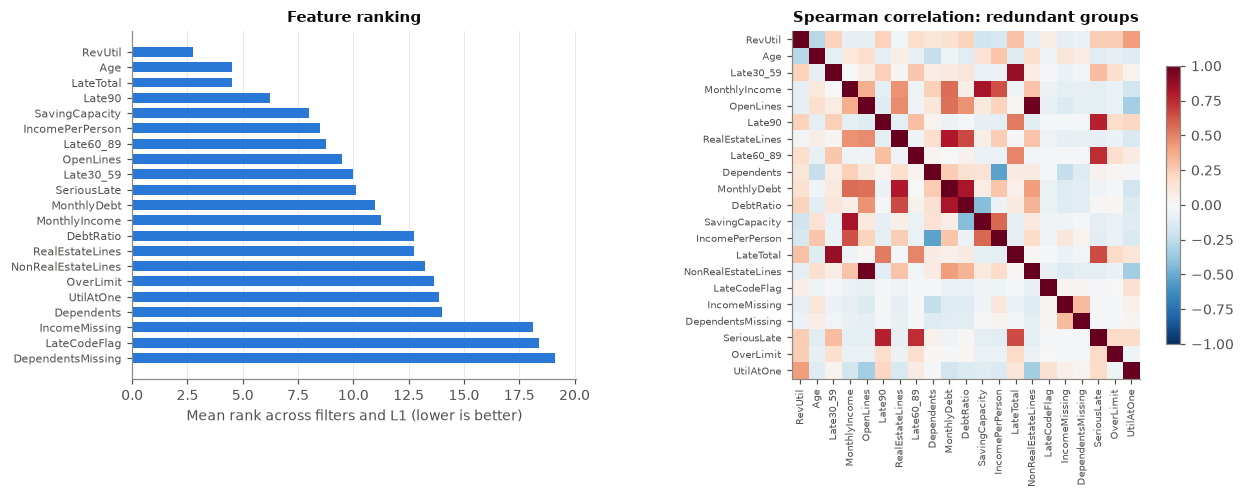

Pairs with |Spearman| >= 0.8:
OpenLines      NonRealEstateLines   0.973
Late30_59      LateTotal            0.871
MonthlyIncome  SavingCapacity       0.821
MonthlyDebt    DebtRatio            0.813


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})

order = ranking.index[::-1]
axes[0].barh(order, ranking.loc[order, "mean rank"], color=COLOR_NO_DEFAULT, height=0.65)
axes[0].set_xlabel("Mean rank across filters and L1 (lower is better)")
axes[0].set_title("Feature ranking")
axes[0].tick_params(axis="y", labelsize=7.5)
axes[0].grid(axis="y", visible=False)

correlation = train_ready[ALL_FEATURES].corr(method="spearman")
image = axes[1].imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(ALL_FEATURES)), ALL_FEATURES, rotation=90, fontsize=6.5)
axes[1].set_yticks(range(len(ALL_FEATURES)), ALL_FEATURES, fontsize=6.5)
axes[1].grid(False)
axes[1].set_title("Spearman correlation: redundant groups")
fig.colorbar(image, ax=axes[1], shrink=0.8)
fig.tight_layout()
plt.show()

upper = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), 1)).stack()
print("Pairs with |Spearman| >= 0.8:")
print(upper[upper.abs() >= 0.8].sort_values(key=np.abs, ascending=False).round(3).to_string())

In [32]:
def cv_auc(columns, frame=train_model, target=y_train):
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    folds = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_score(model, frame[columns], target, cv=folds, scoring="roc_auc").mean()


SELECTED = [
    "RevUtil", "OverLimit",
    "Late30_59", "Late60_89", "Late90", "LateCodeFlag",
    "MonthlyIncome", "MonthlyDebt", "DebtRatio", "SavingCapacity", "IncomePerPerson", "IncomeMissing",
    "OpenLines", "RealEstateLines",
    "Age",
]

candidates = {
    "All features": ALL_FEATURES,
    "Original variables and flags": ["RevUtil", "Age", "MonthlyIncome", "MonthlyDebt", "OpenLines", "RealEstateLines",
                                     "Dependents"] + LATE_COLS + ["LateCodeFlag", "IncomeMissing", "DependentsMissing"],
    "Selected": SELECTED,
}
pd.Series({name: cv_auc(cols) for name, cols in candidates.items()}, name="5-fold CV AUC").to_frame().assign(
    features=[len(c) for c in candidates.values()])

,5-fold CV AUC,features
All features,0.861,21
Original variables and flags,0.856,13
Selected,0.858,15


**What the ranking shows.** Payment history and utilisation come first under every criterion, which matches credit-risk practice, followed by age. Every p-value is effectively 0, so significance alone would have kept everything.

We do not follow the ranking blindly. It undervalues rare but critical flags (`LateCodeFlag` covers 0.2% of customers, yet they default 55% of the time), and Relief gives binary features scores near zero by design. The redundant pairs above also show that some features repeat each other. So we combine the evidence with what the IDSS needs: variables an employee can read and explain.

**Decision: we remove six features.**

| Removed | Why |
|---|---|
| `NonRealEstateLines` | Almost a copy of `OpenLines` (correlation 0.97) |
| `LateTotal`, `SeriousLate` | Summaries of the three lateness counts, which are clearer to read one by one |
| `UtilAtOne` | L1 drops it, and it has the worst RFE rank (6) |
| `Dependents`, `DependentsMissing` | Weak signal and sensitive; `IncomePerPerson` already reflects household size |

We keep `IncomeMissing` and `LateCodeFlag` despite their low ranks: `IncomeMissing` tells the employee that the income is an estimate, and `LateCodeFlag` carries the signal from section 4.2.

**Result.** 15 features instead of 21, for a loss of 0.003 in cross-validated AUC (0.861 to 0.858). We accept this small loss in exchange for a model that is easier to explain. The exported files still contain all 21 features, in case the modelling stage needs them.

### Dimensionality reduction

We check whether PCA could summarise the 15 features in a few components without losing predictive power.

In [33]:
pca = PCA().fit(train_model[SELECTED])
cumulative = np.cumsum(pca.explained_variance_ratio_)
print("Components for 80% / 95% of variance:", np.argmax(cumulative >= .8) + 1, "/", np.argmax(cumulative >= .95) + 1,
      "of", len(SELECTED))

folds = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
n_80 = np.argmax(cumulative >= .8) + 1
pca_model = make_pipeline(PCA(n_components=n_80), LogisticRegression(max_iter=1000, class_weight="balanced"))
print(f"CV AUC, {len(SELECTED)} selected features: {cv_auc(SELECTED):.4f}")
print(f"CV AUC, {n_80} principal components:   "
      f"{cross_val_score(pca_model, train_model[SELECTED], y_train, cv=folds, scoring='roc_auc').mean():.4f}")

Components for 80% / 95% of variance: 7 / 10 of 15
CV AUC, 15 selected features: 0.8576
CV AUC, 7 principal components:   0.8502


**Decision: we do not use PCA.** *Why:* the features do not collapse into a few dimensions (we need 7 components to keep 80% of the variance), and the AUC drops from 0.858 to 0.850. Above all, a component that mixes income, debt and age cannot be explained to a customer who has been refused a loan.

## 12. Instance selection and class imbalance

We remove no customers: sections 4 and 8 found none that are irrelevant or wrong beyond repair, and we keep the duplicates. Two things remain: checking that the training and test sets look alike, and deciding what to do about the low default rate.

In [34]:
shift = pd.DataFrame({
    col: {"KS statistic": stats.ks_2samp(train_ready[col], test_ready[col]).statistic,
          "p": stats.ks_2samp(train_ready[col], test_ready[col]).pvalue}
    for col in NUMERIC
}).T
print(f"Largest KS distance between train and test: {shift['KS statistic'].max():.4f} ({shift['KS statistic'].idxmax()})")
print(f"Lowest p-value: {shift['p'].min():.3f}")

positive_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Default rate: train {y_train.mean():.3%}, test {test_ready[TARGET].mean():.3%}")
print(f"Non-defaults per default: {positive_weight:.2f}")

Largest KS distance between train and test: 0.0082 (RevUtil)
Lowest p-value: 0.078
Default rate: train 6.684%, test 6.683%
Non-defaults per default: 13.96


**Train and test look alike.** The largest difference between their distributions is tiny (a Kolmogorov-Smirnov distance of 0.008, for `RevUtil`), and no variable differs significantly (lowest p = 0.078). Results on the test set will therefore describe the data fairly.

**Decision: we do not rebalance the saved data.** There are about 14 non-defaulters for every defaulter, but:
- the test set must keep the real 6.7% rate, or its results would not describe real customers;
- training on rebalanced data distorts the predicted probabilities, and the employee needs an honest probability of default;
- oversampling only repeats rows, and undersampling would throw away most of the valid data.

**How the modelling stage should handle it instead:** with **class weights** (for example `scale_pos_weight` of about 14 in XGBoost or LightGBM; we save this value in the export), with metrics suited to rare events such as ROC-AUC and PR-AUC rather than accuracy, and with a decision threshold set from the bank's costs. If resampling is tried, it must happen only inside the training folds.

## 13. Final descriptive analysis (data improvements)

We end by measuring what the preprocessing changed, first in the data itself and then in how well models can use it.

In [35]:
before = raw.loc[train.index]
rows = []
for name, old, new in [
    ("Debt ratio", before["DebtRatioRaw"], train_ready["DebtRatio"]),
    ("Monthly income", before["MonthlyIncome"], train_ready["MonthlyIncome"]),
    ("Revolving utilisation", before["RevUtil"], train_ready["RevUtil"]),
    ("Dependents", before["Dependents"], train_ready["Dependents"]),
    ("Age", before["Age"], train_ready["Age"]),
    ("Late 30-59 days", before["Late30_59"], train_ready["Late30_59"]),
    ("Late 90+ days", before["Late90"], train_ready["Late90"]),
]:
    rows.append({"variable": name, "missing, before": old.isna().sum(), "missing, after": new.isna().sum(),
                 "mean, before": old.mean(), "mean, after": new.mean(),
                 "std, before": old.std(), "std, after": new.std(),
                 "max, before": old.max(), "max, after": new.max(),
                 "skew, before": old.skew(), "skew, after": new.skew()})
display(pd.DataFrame(rows).set_index("variable").T)

report = pd.DataFrame({
    "Stage": ["Raw file", "After corrections", "Train after imputation", "Test after imputation"],
    "Rows": [len(raw), len(clean), len(train_ready), len(test_ready)],
    "Missing cells": [raw.isna().sum().sum(), clean.isna().sum().sum(),
                      train_ready.isna().sum().sum(), test_ready.isna().sum().sum()],
    "Columns": [raw.shape[1], clean.shape[1], train_ready.shape[1], test_ready.shape[1]],
})
report

variable,Debt ratio,Monthly income,Revolving utilisation,Dependents,Age,Late 30-59 days,Late 90+ days
"missing, before",0.000,"23,675.000",0.000,"3,128.000",0.000,0.000,0.000
"missing, after",0.000,0.000,0.000,0.000,0.000,0.000,0.000
"mean, before",352.271,"6,651.507",6.129,0.757,52.288,0.420,0.265
"mean, after",0.359,"6,430.219",0.322,0.738,52.288,0.245,0.090
"std, before","2,093.710","14,541.181",253.361,1.115,14.771,4.182,4.158
"std, after",0.913,"13,055.162",0.365,1.107,14.771,0.697,0.482
"max, before","329,664.000","3,008,750.000","50,708.000",20.000,109.000,98.000,98.000
"max, after",170.823,"3,008,750.000",7.309,20.000,109.000,13.000,17.000
"skew, before",99.144,122.590,100.539,1.599,0.186,22.657,23.156
"skew, after",84.294,136.028,1.454,1.636,0.187,4.282,9.357


,Stage,Rows,Missing cells,Columns
0,Raw file,150000,33655,11
1,After corrections,150000,37005,14
2,Train after imputation,120000,0,22
3,Test after imputation,30000,0,22


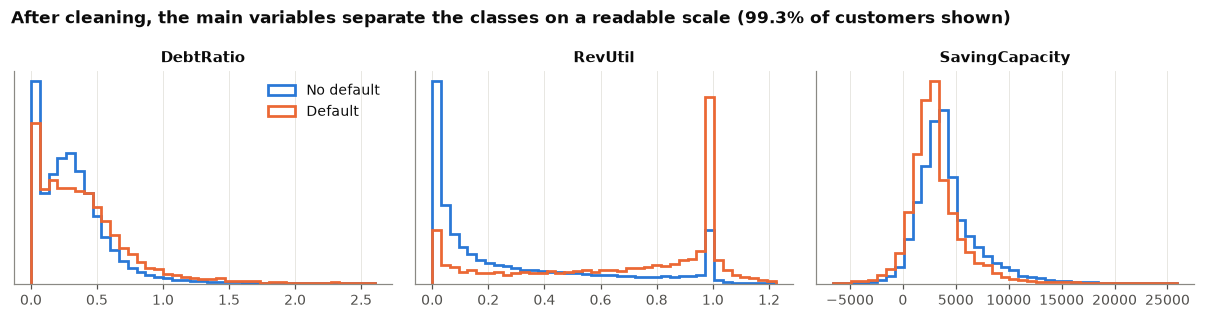

Single-variable AUC (higher = better separation):
  DebtRatio before: 0.5222
  DebtRatio after:  0.5638
  RevUtil before:   0.7778
  RevUtil after:    0.7782
  Late90 before:    0.6581
  Late90 after:     0.6511


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9))
for ax, col, title in [(axes[0], "DebtRatio", "DebtRatio"), (axes[1], "RevUtil", "RevUtil"),
                       (axes[2], "SavingCapacity", "SavingCapacity")]:
    values = train_ready[col]
    low, high = values.quantile([.002, .995])
    bins = np.linspace(low, high, 40)
    for flag, color, label in [(0, COLOR_NO_DEFAULT, "No default"), (1, COLOR_DEFAULT, "Default")]:
        ax.hist(values[train_ready[TARGET] == flag], bins=bins, density=True,
                histtype="step", linewidth=1.8, color=color, label=label)
    ax.set_title(title)
    ax.set_yticks([])
axes[0].legend(frameon=False)
fig.suptitle("After cleaning, the main variables separate the classes on a readable scale (99.3% of customers shown)",
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

print("Single-variable AUC (higher = better separation):")
print(f"  DebtRatio before: {roc_auc_score(before[TARGET], before['DebtRatioRaw']):.4f}")
print(f"  DebtRatio after:  {roc_auc_score(train_ready[TARGET], train_ready['DebtRatio']):.4f}")
print(f"  RevUtil before:   {roc_auc_score(before[TARGET], before['RevUtil']):.4f}")
print(f"  RevUtil after:    {roc_auc_score(train_ready[TARGET], train_ready['RevUtil']):.4f}")
print(f"  Late90 before:    {roc_auc_score(before[TARGET], before['Late90']):.4f}")
print(f"  Late90 after:     {roc_auc_score(train_ready[TARGET], train_ready['Late90']):.4f}")

As a last check, we compare the raw data (with only a median fill, as a quick analysis would do) against our prepared data, with 5-fold cross-validation on the training set; the test set stays untouched for the modelling stage. We use two models: logistic regression, which is simple and transparent, and gradient boosting, a strong tree-based model. We also measure what removing the sensitive variables from section 2 would cost. One small caveat: we fitted the fills and the scaling on the whole training set rather than inside each fold, which makes all these scores very slightly optimistic.

In [37]:
raw_features = [c for c in raw.columns if c != TARGET]
raw_filled = before[raw_features].fillna(before[raw_features].median())
folds = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)


def score(model, X, y):
    return cross_val_score(model, X, y, cv=folds, scoring="roc_auc").mean()


logistic = LogisticRegression(max_iter=2000, class_weight="balanced")
scaled_logistic = make_pipeline(StandardScaler(), logistic)
boosting = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

SENSITIVE = ["Age", "Dependents", "IncomePerPerson", "DependentsMissing"]
without_sensitive = [c for c in SELECTED if c not in SENSITIVE]

pd.DataFrame({
    "Logistic regression": [score(scaled_logistic, raw_filled, before[TARGET]),
                            score(logistic, train_model[SELECTED], y_train),
                            score(logistic, train_model[without_sensitive], y_train)],
    "Gradient boosting": [score(boosting, raw_filled, before[TARGET]),
                          score(boosting, train_ready[SELECTED], y_train),
                          score(boosting, train_ready[without_sensitive], y_train)],
}, index=["Raw data, median fill", "Prepared, selected features", "Prepared, without sensitive variables"])

,Logistic regression,Gradient boosting
"Raw data, median fill",0.789,0.863
"Prepared, selected features",0.858,0.863
"Prepared, without sensitive variables",0.854,0.860


### Data improvements report

**What changed in the data**
- We went from about 34,000 missing cells to 0 without deleting any customer. All 150,000 remain, and the default rate is unchanged.
- `DebtRatio` now means what its name says: its mean fell from 352 to 0.36, and on its own it predicts default better (AUC from 0.522 to 0.564).
- The impossible values are gone: a utilisation of 50,708, 98 late payments, age 0.
- `Late90` on its own predicts slightly worse (AUC from 0.658 to 0.651). We expect this, because the code rows moved to `LateCodeFlag`, which now carries that signal.

**What changed for the models**

| Model | Raw data | Prepared | Prepared, without sensitive variables |
|---|---|---|---|
| Logistic regression | 0.789 | 0.858 | 0.854 |
| Gradient boosting | 0.863 | 0.863 | 0.860 |

- **Logistic regression gains 0.07 AUC**, because a linear model cannot cope with mixed units and extreme skew.
- **Gradient boosting gains nothing.** Trees are not affected by skew and can work around a mixed-unit column on their own. For a tree model, the value of our work is not a higher score but variables that mean what they say, so the explanations shown to the employee are true. "DebtRatio of 1,159" means nothing; "debt is 40% of income" is something an employee can use.
- After preparation, logistic regression comes within 0.005 of boosting, so a transparent model is a realistic choice for the IDSS.
- Removing the sensitive variables costs only 0.003-0.004 AUC, so the bank could reasonably leave them out. That is a decision for the bank and its ethics or legal team, not one the data can make.

## 14. Export and handover to the IDSS

We save everything the next stage needs to `data/processed/` (ignored by git; running this notebook recreates it):

| File | Contents | Use |
|---|---|---|
| `train_readable.csv`, `test_readable.csv` | All features in original units | Tree models, explanations in dollars |
| `train_model.csv`, `test_model.csv` | All features, logged and standardised | Logistic regression, KNN, other scale-sensitive methods |
| `preprocessing.joblib` | Medians, income model, scaler, feature lists, rules, class weight | Applying identical steps to a new customer |

A new customer will come through a form, not through the raw file, so the IDSS should ask for `MonthlyDebt` directly instead of rebuilding it from a ratio. We write `prepare_customer`, which takes that form input and applies exactly the same steps as in training. Blank fields are allowed and are handled like missing values in training. Below we check that it reproduces the prepared test set exactly, and then score an example customer with undeclared income.

In [38]:
OUTPUT = Path("../data/processed")
OUTPUT.mkdir(exist_ok=True)

train_ready.to_csv(OUTPUT / "train_readable.csv")
test_ready.to_csv(OUTPUT / "test_readable.csv")
train_model.to_csv(OUTPUT / "train_model.csv")
test_model.to_csv(OUTPUT / "test_model.csv")

artifacts = {
    "medians": medians,
    "income_imputer": income_imputer,
    "scaler": scaler,
    "numeric": NUMERIC,
    "binary": BINARY,
    "selected_features": SELECTED,
    "sensitive_features": SENSITIVE,
    "log_columns": LOG_COLS,
    "signed_log_columns": SIGNED_LOG_COLS,
    "rules": {"income_floor": INCOME_FLOOR, "util_ceiling": UTIL_CEILING, "min_age": MIN_AGE},
    "positive_class_weight": positive_weight,
}
joblib.dump(artifacts, OUTPUT / "preprocessing.joblib")


def prepare_customer(customers):
    """Cleaned-schema customers (form input, blanks allowed) to the readable and model feature tables."""
    out = customers.copy()
    out["IncomeMissing"] = (out["MonthlyIncome"].isna() | out["MonthlyIncome"].le(INCOME_FLOOR)).astype("int8")
    out["DependentsMissing"] = out["Dependents"].isna().astype("int8")
    out["LateCodeFlag"] = out.get("LateCodeFlag", pd.Series(0, index=out.index)).astype("int8")
    out["MonthlyIncome"] = out["MonthlyIncome"].where(out["MonthlyIncome"] > INCOME_FLOOR)
    readable = derive(impute(out, medians, income_imputer))
    return readable, to_model_scale(readable)


# Check: the function must reproduce the prepared test set exactly.
replayed_readable, replayed_model = prepare_customer(test.drop(columns=[TARGET, "IncomeMissing", "DependentsMissing"]))
pd.testing.assert_frame_equal(replayed_readable[ALL_FEATURES], test_ready[ALL_FEATURES], check_dtype=False)
pd.testing.assert_frame_equal(replayed_model[ALL_FEATURES], test_model[ALL_FEATURES], check_dtype=False)
print("prepare_customer reproduces the test set exactly.")

# Saved files must load back and match.
reloaded = joblib.load(OUTPUT / "preprocessing.joblib")
assert reloaded["selected_features"] == SELECTED
assert pd.read_csv(OUTPUT / "test_readable.csv", index_col=0).shape == test_ready.shape

example = pd.DataFrame([{
    "RevUtil": 0.45, "Age": 38, "Late30_59": 1, "Late60_89": 0, "Late90": 0, "MonthlyIncome": np.nan,
    "OpenLines": 6, "RealEstateLines": 1, "Dependents": np.nan, "MonthlyDebt": 1800,
}])
example_readable, _ = prepare_customer(example)
print("\nExample customer with undeclared income and dependents:")
example_readable[["MonthlyIncome", "Dependents", "DebtRatio", "SavingCapacity", "IncomeMissing", "DependentsMissing"]]

prepare_customer reproduces the test set exactly.

Example customer with undeclared income and dependents:


,MonthlyIncome,Dependents,DebtRatio,SavingCapacity,IncomeMissing,DependentsMissing
0,"4,457.993",0.000,0.404,"2,657.993",1,1


### Notes for the IDSS stage

1. **Use the test set once.** We have not used it for any decision; it should be kept for the final evaluation.
2. **Handle imbalance with class weights** and a threshold based on the bank's costs, and evaluate with ROC-AUC and PR-AUC, not accuracy (section 12).
3. **Show uncertainty.** Whenever `IncomeMissing = 1`, the interface should say that the income is an estimate and ask for the real figure.
4. **Send `LateCodeFlag` customers to manual review**, because the meaning of the codes is undocumented and should be confirmed with the data provider.
5. **Keep the population limits in mind** (section 2): the model learns from customers who already received credit, from a non-European portfolio of unknown date.
6. **Decide on the sensitive variables** before training, and keep a human as the decision-maker.